# Solar Power Prediction Application

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm requests joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime, timedelta
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import joblib
import requests

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

## Step 1 – Generate the dataset

In [3]:
np.random.seed(42)

rows = []
start = datetime(2024, 1, 1)

for i in range(24 * 60):
    timestamp = start + timedelta(hours=i)
    hour = timestamp.hour

    temperature = 18 + 10 * np.sin((hour / 24) * 2 * np.pi) + np.random.normal(0, 1)
    humidity = np.clip(60 + np.random.normal(0, 10), 20, 100)
    cloud_cover = np.clip(np.random.normal(40, 25), 0, 100)
    wind_speed = np.clip(np.random.normal(5, 2), 0, 15)
    precipitation = max(0, np.random.normal(0.2, 0.5))

    daylight_factor = max(0, np.sin((hour - 6) / 12 * np.pi))

    solar_output = max(
        0,
        daylight_factor * (1 - cloud_cover / 120) * (temperature / 30) * 1000
    )
    solar_output = max(0, solar_output + np.random.normal(0, 20))

    rows.append([
        timestamp.strftime("%Y-%m-%d %H:%M:%S"),
        temperature,
        humidity,
        cloud_cover,
        wind_speed,
        precipitation,
        solar_output
    ])

df = pd.DataFrame(rows, columns=[
    "timestamp", "temperature", "humidity", "cloud_cover",
    "wind_speed", "precipitation", "solar_output"
])

df.to_csv("solar_weather_dataset.csv", index=False)
print("Dataset created successfully.")

Dataset created successfully.


## Step 2 – Load the CSV file

In [4]:
df = pd.read_csv("solar_weather_dataset.csv")

df.head()

,timestamp,temperature,humidity,cloud_cover,wind_speed,precipitation,solar_output
0,2024-01-01 00:00:00,18.496714,58.617357,56.192213,8.046060,0.082923,0.000000
1,2024-01-01 01:00:00,22.167403,67.674347,28.263140,6.085120,0.000000,0.000000
2,2024-01-01 02:00:00,23.241962,40.867198,0.000000,3.875425,0.000000,6.284947
3,2024-01-01 03:00:00,24.163044,45.876963,76.641219,4.548447,0.233764,0.000000
4,2024-01-01 04:00:00,26.115871,61.109226,11.225161,5.751396,0.000000,0.000000


In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (1440, 7)

Column names:
['timestamp', 'temperature', 'humidity', 'cloud_cover', 'wind_speed', 'precipitation', 'solar_output']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      1440 non-null   object 
 1   temperature    1440 non-null   float64
 2   humidity       1440 non-null   float64
 3   cloud_cover    1440 non-null   float64
 4   wind_speed     1440 non-null   float64
 5   precipitation  1440 non-null   float64
 6   solar_output   1440 non-null   float64
dtypes: float64(6), object(1)
memory usage: 78.9+ KB


## Step 3 – Understand and clean the data

In [6]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:


timestamp        0
temperature      0
humidity         0
cloud_cover      0
wind_speed       0
precipitation    0
solar_output     0
dtype: int64

Duplicate rows: 0


In [7]:
df = df.drop_duplicates()

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

df = df.sort_values("timestamp").reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
display(df.isnull().sum())

Shape after cleaning: (1440, 7)
Missing values after cleaning:


timestamp        0
temperature      0
humidity         0
cloud_cover      0
wind_speed       0
precipitation    0
solar_output     0
dtype: int64

In [8]:
df.describe()

,timestamp,temperature,humidity,cloud_cover,wind_speed,precipitation,solar_output
count,1440,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
mean,2024-01-30 23:30:00,18.011275,59.927168,40.933509,4.935842,0.305993,130.349056
min,2024-01-01 00:00:00,5.364252,30.088640,0.000000,0.000000,0.000000,0.000000
25%,2024-01-15 23:45:00,11.052016,52.925227,23.497798,3.502491,0.000000,0.000000
50%,2024-01-30 23:30:00,17.937356,60.017787,40.542900,4.932755,0.169943,27.414800
75%,2024-02-14 23:15:00,24.878563,66.936299,56.976339,6.267663,0.519522,230.244414
max,2024-02-29 23:00:00,31.098299,91.931076,100.000000,12.852475,1.888691,724.409048
std,NaN,7.122608,10.031519,23.696147,2.040865,0.365032,171.909959


### Check outliers

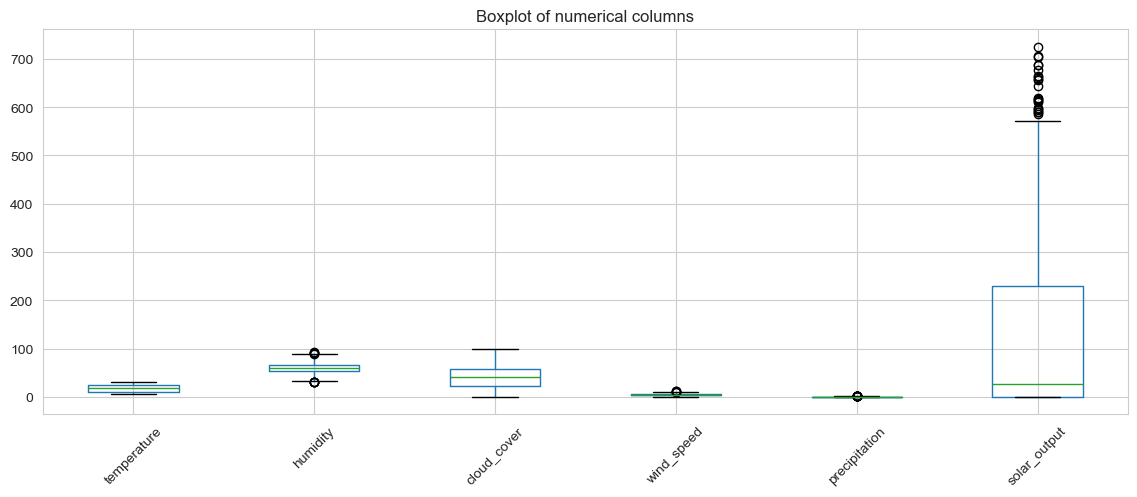

In [9]:
plt.figure(figsize=(14, 5))
df[numeric_columns].boxplot()
plt.title("Boxplot of numerical columns")
plt.xticks(rotation=45)
plt.show()

## Step 4 – Exploratory Data Analysis (EDA)

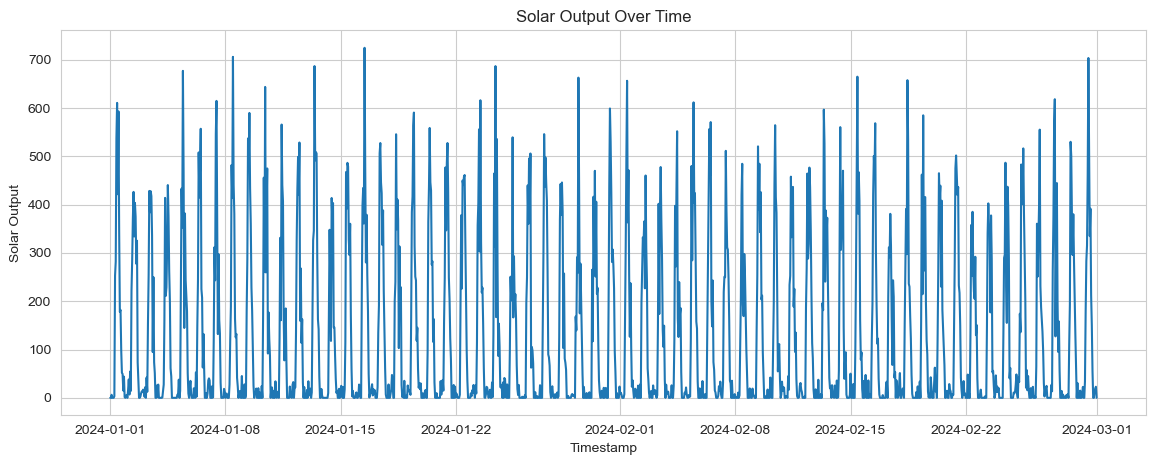

In [10]:
plt.figure(figsize=(14, 5))
plt.plot(df["timestamp"], df["solar_output"])
plt.title("Solar Output Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Solar Output")
plt.show()

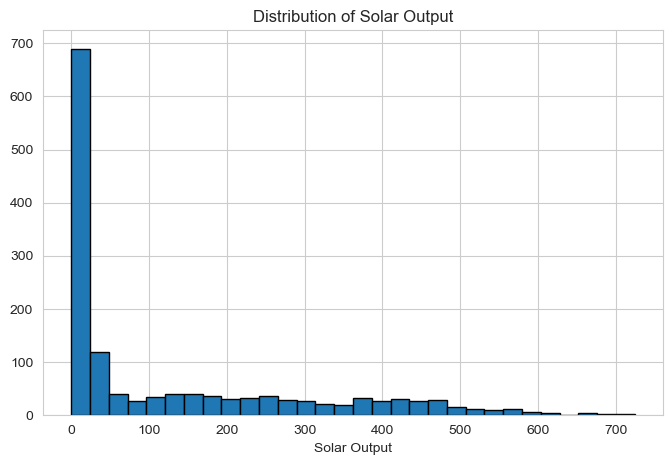

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df["solar_output"], bins=30, edgecolor="black")
plt.title("Distribution of Solar Output")
plt.xlabel("Solar Output")
plt.show()

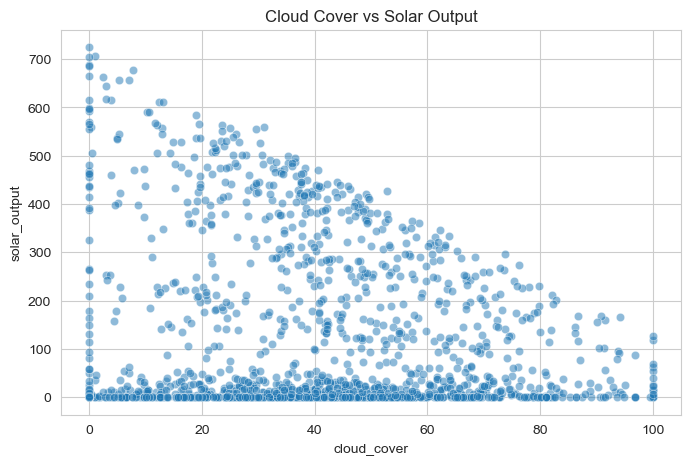

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="cloud_cover", y="solar_output", alpha=0.5)
plt.title("Cloud Cover vs Solar Output")
plt.show()

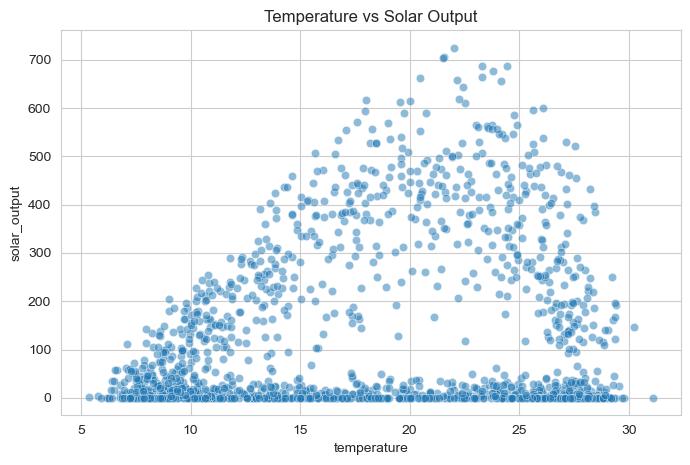

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="temperature", y="solar_output", alpha=0.5)
plt.title("Temperature vs Solar Output")
plt.show()

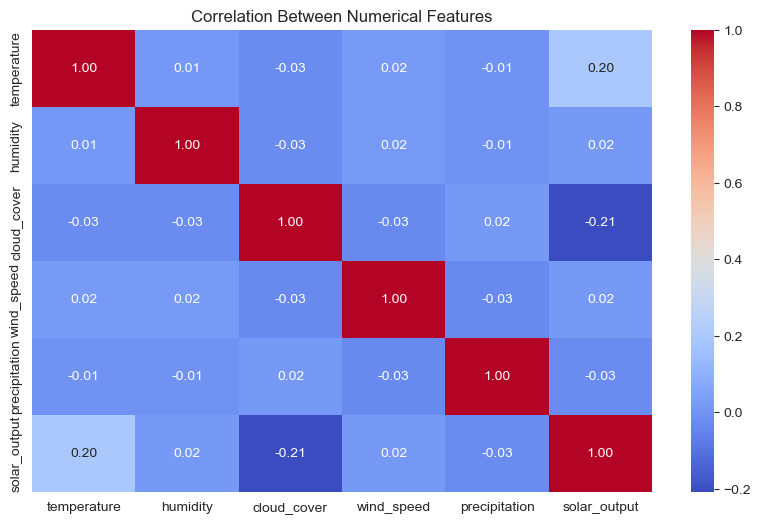

In [14]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.show()

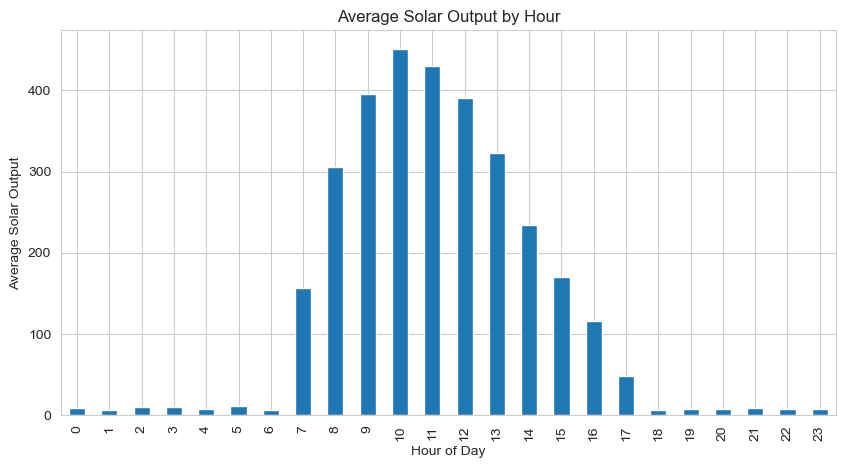

In [15]:
df["hour"] = df["timestamp"].dt.hour

hourly_output = df.groupby("hour")["solar_output"].mean()

plt.figure(figsize=(10, 5))
hourly_output.plot(kind="bar")
plt.title("Average Solar Output by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Solar Output")
plt.show()

## Step 5 – Feature engineering

In [16]:
df["hour"] = df["timestamp"].dt.hour
df["day"] = df["timestamp"].dt.day
df["month"] = df["timestamp"].dt.month
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df.head()

,timestamp,temperature,humidity,cloud_cover,wind_speed,precipitation,solar_output,hour,day,month,day_of_week,is_weekend,hour_sin,hour_cos
0,2024-01-01 00:00:00,18.496714,58.617357,56.192213,8.046060,0.082923,0.000000,0,1,1,0,0,0.000000,1.000000
1,2024-01-01 01:00:00,22.167403,67.674347,28.263140,6.085120,0.000000,0.000000,1,1,1,0,0,0.258819,0.965926
2,2024-01-01 02:00:00,23.241962,40.867198,0.000000,3.875425,0.000000,6.284947,2,1,1,0,0,0.500000,0.866025
3,2024-01-01 03:00:00,24.163044,45.876963,76.641219,4.548447,0.233764,0.000000,3,1,1,0,0,0.707107,0.707107
4,2024-01-01 04:00:00,26.115871,61.109226,11.225161,5.751396,0.000000,0.000000,4,1,1,0,0,0.866025,0.500000


## Step 6 – Select features and target

Our target is `solar_output`. The other selected columns will be used as input features.

In [17]:
features = [
    "temperature",
    "humidity",
    "cloud_cover",
    "wind_speed",
    "precipitation",
    "hour",
    "day",
    "month",
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

X = df[features]
y = df["solar_output"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1440, 12)
Target shape: (1440,)


## Step 7 – Train-test split 
As requested, we will shuffle the rows before splitting. We use 80% for training and 20% for testing.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1152
Testing rows: 288


## Step 8 – Train the three models

In [19]:
random_forest = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

xgboost_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective="reg:squarederror"
)

lightgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

random_forest.fit(X_train, y_train)
xgboost_model.fit(X_train, y_train)
lightgbm_model.fit(X_train, y_train)

print("All three models trained successfully.")

All three models trained successfully.


## Step 9 – Evaluate and compare models

We will compare:
- **MAE:** Average absolute prediction error. Lower is better.
- **RMSE:** Penalizes larger errors more. Lower is better.
- **R²:** How much variation the model explains. Closer to 1 is generally better.

In [20]:
models = {
    "Random Forest": random_forest,
    "XGBoost": xgboost_model,
    "LightGBM": lightgbm_model
}

results = []
predictions = {}

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    y_pred = np.clip(y_pred, 0, None)

    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

,Model,MAE,RMSE,R2 Score
0,XGBoost,14.540258,18.906635,0.986213
1,LightGBM,15.505055,20.535749,0.983735
2,Random Forest,16.410469,22.681668,0.980158


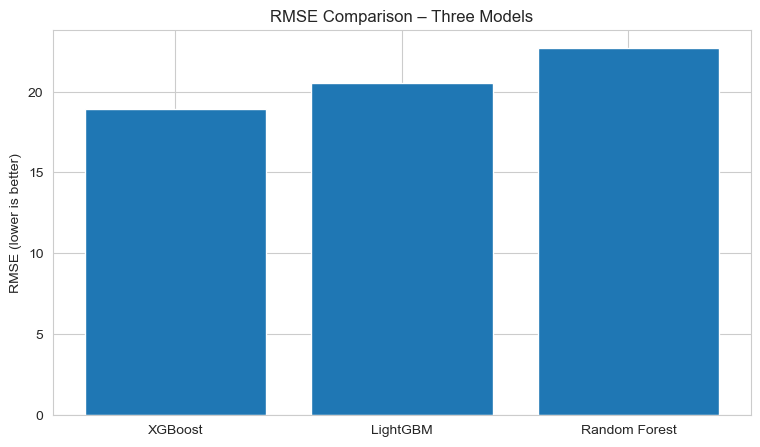

In [21]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison – Three Models")
plt.ylabel("RMSE (lower is better)")
plt.show()

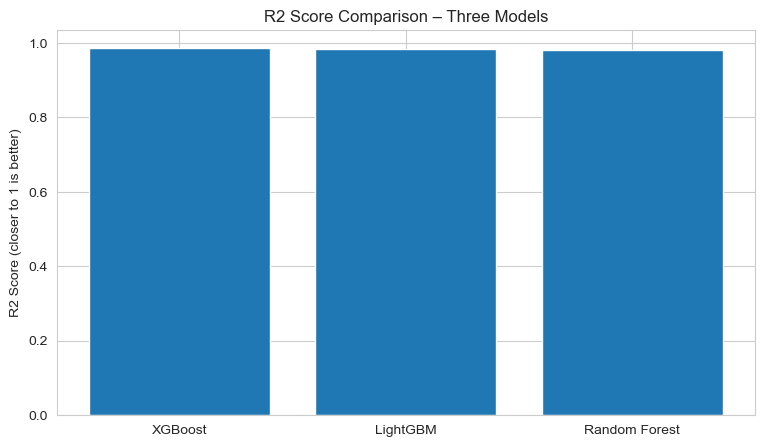

In [22]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R2 Score Comparison – Three Models")
plt.ylabel("R2 Score (closer to 1 is better)")
plt.show()

In [23]:
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Best model based on lowest RMSE:", best_model_name)

Best model based on lowest RMSE: XGBoost


## Step 10 – Try an ensemble only if needed

If the best individual model has an R² score below 0.85, we will try combining all three models with a Voting Regressor. Otherwise, we will keep the best individual model.

The 0.85 value is a practical experiment threshold for this notebook, not a guarantee of quality. We will still compare the ensemble using the same test data.

In [24]:
ensemble_tried = False
final_model = best_model
final_model_name = best_model_name
best_model_score = results_df.loc[0, "RMSE"]

if results_df.loc[0, "R2 Score"] < 0.85:
    ensemble_model = VotingRegressor(
        estimators=[
            ("random_forest", random_forest),
            ("xgboost", xgboost_model),
            ("lightgbm", lightgbm_model)
        ]
    )

    ensemble_model.fit(X_train, y_train)

    ensemble_pred = np.clip(ensemble_model.predict(X_test), 0, None)

    ensemble_result = {
        "Model": "Ensemble",
        "MAE": mean_absolute_error(y_test, ensemble_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, ensemble_pred)),
        "R2 Score": r2_score(y_test, ensemble_pred)
    }

    results_df = pd.concat(
        [results_df, pd.DataFrame([ensemble_result])],
        ignore_index=True
    ).sort_values("RMSE").reset_index(drop=True)

    ensemble_tried = True

    if ensemble_result["RMSE"] < best_model_score:
        final_model = ensemble_model
        final_model_name = "Ensemble"

display(results_df)
print("Final selected model:", final_model_name)

,Model,MAE,RMSE,R2 Score
0,XGBoost,14.540258,18.906635,0.986213
1,LightGBM,15.505055,20.535749,0.983735
2,Random Forest,16.410469,22.681668,0.980158


Final selected model: XGBoost


## Step 11 – Actual vs predicted graph

This graph checks how close the selected model's predictions are to the actual test values.

,Actual,Predicted
0,0.000000,7.449501
1,5.336368,11.248585
2,6.760470,6.468144
3,51.081386,49.020226
4,0.000000,6.216505
5,1.892421,7.163114
6,6.647537,8.198796
7,33.952476,4.582428
8,0.000000,7.967696
9,8.892053,4.094247


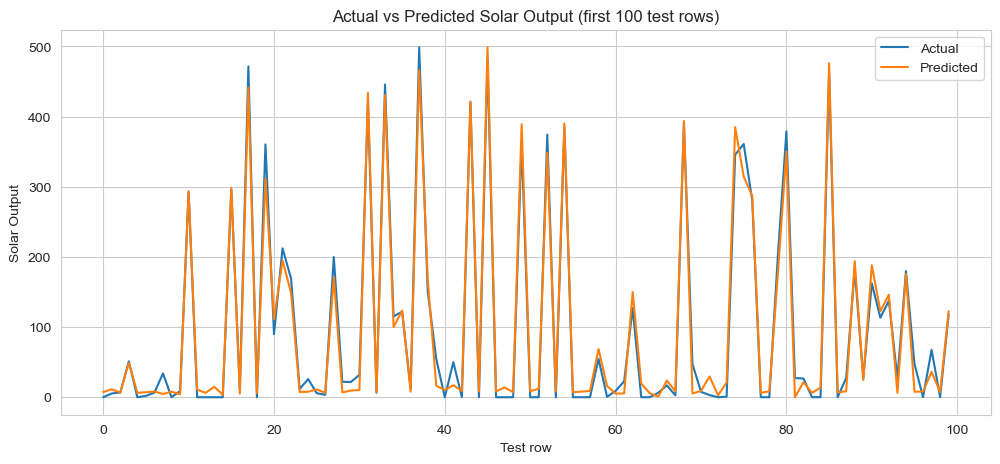

In [25]:
final_predictions = np.clip(final_model.predict(X_test), 0, None)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": final_predictions
})

display(comparison.head(10))

plt.figure(figsize=(12, 5))
plt.plot(comparison["Actual"].values[:100], label="Actual")
plt.plot(comparison["Predicted"].values[:100], label="Predicted")
plt.title("Actual vs Predicted Solar Output (first 100 test rows)")
plt.xlabel("Test row")
plt.ylabel("Solar Output")
plt.legend()
plt.show()

## Step 12 – Feature importance

,Feature,Importance
11,hour_cos,0.818223
5,hour,0.107811
2,cloud_cover,0.039669
0,temperature,0.030869
8,day_of_week,0.000593
6,day,0.000590
4,precipitation,0.000538
1,humidity,0.000503
3,wind_speed,0.000477
10,hour_sin,0.000419


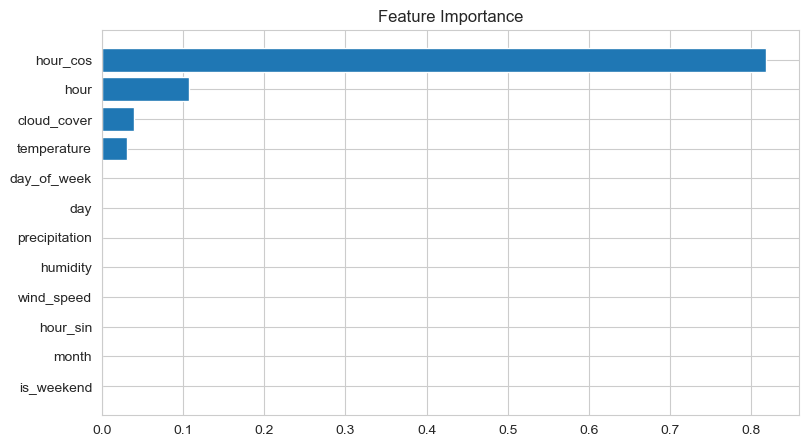

In [26]:
if hasattr(final_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": features,
        "Importance": final_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance_df)

    plt.figure(figsize=(9, 5))
    plt.barh(importance_df["Feature"], importance_df["Importance"])
    plt.gca().invert_yaxis()
    plt.title("Feature Importance")
    plt.show()
else:
    print("Feature importance is not available for the selected model.")

## Step 13 – Save the selected model

In [27]:
joblib.dump(final_model, "solar_power_model.pkl")
joblib.dump(features, "solar_power_features.pkl")

print("Model and feature list saved.")

Model and feature list saved.


## Step 14 – Get new hourly weather data for Pune

Now we will use a **new dataset**, not the original training CSV.

In [28]:
latitude = 18.52
longitude = 73.86

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "cloud_cover",
        "wind_speed_10m",
        "precipitation"
    ],
    "forecast_days": 3,
    "timezone": "Asia/Kolkata"
}

try:
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    weather_data = response.json()
    print("Weather forecast received.")
    api_success = True
except requests.exceptions.RequestException as error:
    print("Weather API could not be reached. Check your internet connection and run this cell again.")
    print("Error:", error)
    api_success = False


Weather forecast received.


In [29]:
if api_success:
    forecast_df = pd.DataFrame({
        "timestamp": pd.to_datetime(weather_data["hourly"]["time"]),
        "temperature": weather_data["hourly"]["temperature_2m"],
        "humidity": weather_data["hourly"]["relative_humidity_2m"],
        "cloud_cover": weather_data["hourly"]["cloud_cover"],
        "wind_speed": weather_data["hourly"]["wind_speed_10m"],
        "precipitation": weather_data["hourly"]["precipitation"]
    })

    forecast_df = forecast_df.dropna().reset_index(drop=True)

    now = pd.Timestamp.now(tz="Asia/Kolkata").tz_localize(None)
    forecast_df = forecast_df[forecast_df["timestamp"] >= now].head(48).copy()

    print("New forecast dataset shape:", forecast_df.shape)
    display(forecast_df.head())
else:
    forecast_df = pd.DataFrame({
        "timestamp": pd.Series(dtype="datetime64[ns]"),
        "temperature": pd.Series(dtype="float"),
        "humidity": pd.Series(dtype="float"),
        "cloud_cover": pd.Series(dtype="float"),
        "wind_speed": pd.Series(dtype="float"),
        "precipitation": pd.Series(dtype="float")
    })
    print("Forecast data is empty because the API request failed. Re-run the API cells when internet is available.")


New forecast dataset shape: (48, 6)


,timestamp,temperature,humidity,cloud_cover,wind_speed,precipitation
14,2026-11-19 14:00:00,28.6,26,0,9.6,0.0
15,2026-11-19 15:00:00,28.4,27,0,9.9,0.0
16,2026-11-19 16:00:00,27.7,28,0,9.9,0.0
17,2026-11-19 17:00:00,26.9,30,0,9.6,0.0
18,2026-11-19 18:00:00,25.6,33,0,8.8,0.0


## Step 15 – Apply the same feature engineering to new data

In [30]:
forecast_df["hour"] = forecast_df["timestamp"].dt.hour
forecast_df["day"] = forecast_df["timestamp"].dt.day
forecast_df["month"] = forecast_df["timestamp"].dt.month
forecast_df["day_of_week"] = forecast_df["timestamp"].dt.dayofweek
forecast_df["is_weekend"] = (forecast_df["day_of_week"] >= 5).astype(int)

forecast_df["hour_sin"] = np.sin(2 * np.pi * forecast_df["hour"] / 24)
forecast_df["hour_cos"] = np.cos(2 * np.pi * forecast_df["hour"] / 24)

new_X = forecast_df[features]

print("New data feature shape:", new_X.shape)
display(new_X.head())

New data feature shape: (48, 12)


,temperature,humidity,cloud_cover,wind_speed,precipitation,hour,day,month,day_of_week,is_weekend,hour_sin,hour_cos
14,28.6,26,0,9.6,0.0,14,19,11,3,0,-0.500000,-8.660254e-01
15,28.4,27,0,9.9,0.0,15,19,11,3,0,-0.707107,-7.071068e-01
16,27.7,28,0,9.9,0.0,16,19,11,3,0,-0.866025,-5.000000e-01
17,26.9,30,0,9.6,0.0,17,19,11,3,0,-0.965926,-2.588190e-01
18,25.6,33,0,8.8,0.0,18,19,11,3,0,-1.000000,-1.836970e-16


## Step 16 – Predict solar output on the new dataset

In [31]:
if len(forecast_df) > 0:
    loaded_model = joblib.load("solar_power_model.pkl")
    loaded_features = joblib.load("solar_power_features.pkl")

    new_X = forecast_df[loaded_features]

    forecast_df["predicted_solar_output"] = np.clip(
        loaded_model.predict(new_X),
        0,
        None
    )

    prediction_table = forecast_df[[
        "timestamp",
        "predicted_solar_output"
    ]]

    display(prediction_table.head(24))
else:
    prediction_table = pd.DataFrame(columns=["timestamp", "predicted_solar_output"])
    print("No new predictions were generated because weather data is unavailable.")


,timestamp,predicted_solar_output
14,2026-11-19 14:00:00,570.879883
15,2026-11-19 15:00:00,565.091553
16,2026-11-19 16:00:00,533.831970
17,2026-11-19 17:00:00,241.735077
18,2026-11-19 18:00:00,8.136694
19,2026-11-19 19:00:00,7.949270
20,2026-11-19 20:00:00,6.445243
21,2026-11-19 21:00:00,12.888604
22,2026-11-19 22:00:00,7.617254
23,2026-11-19 23:00:00,11.403280


## Step 17 – Final visualization: recent history + future predictions

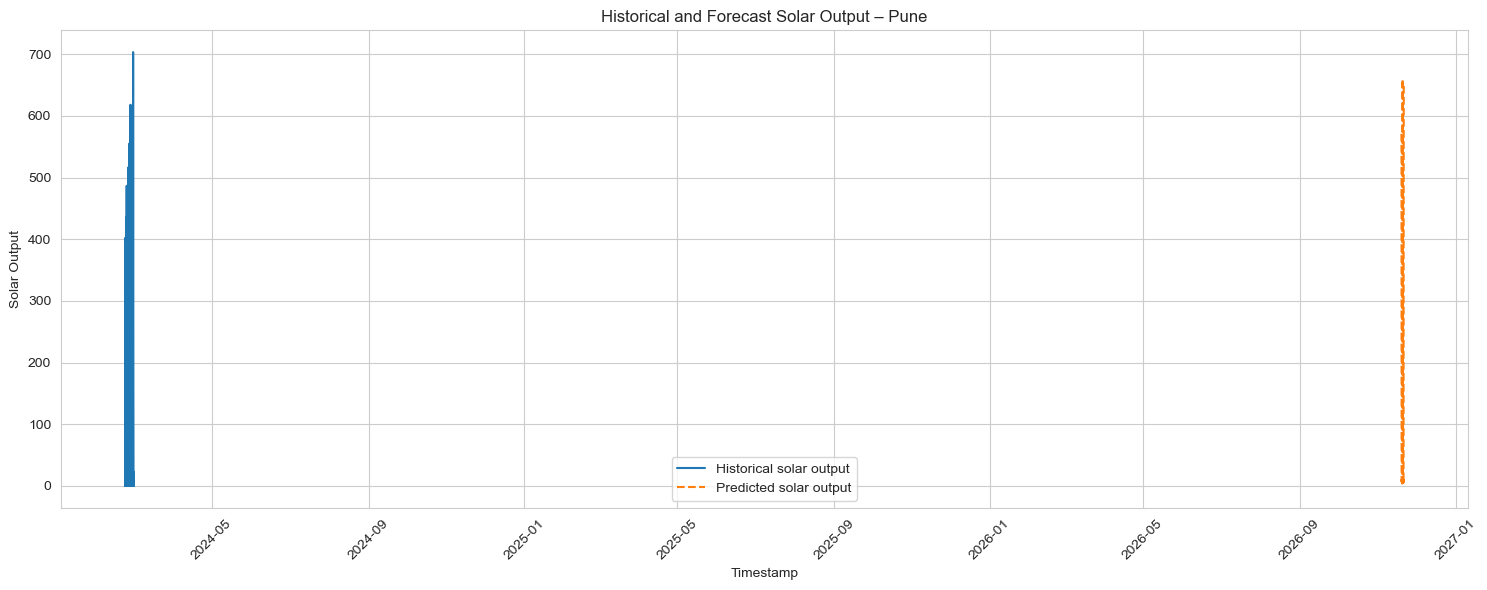

In [32]:
if len(forecast_df) > 0:
    historical_data = df[["timestamp", "solar_output"]].copy()
    historical_data = historical_data.tail(24 * 7)

    plt.figure(figsize=(15, 6))
    plt.plot(
        historical_data["timestamp"],
        historical_data["solar_output"],
        label="Historical solar output"
    )
    plt.plot(
        forecast_df["timestamp"],
        forecast_df["predicted_solar_output"],
        label="Predicted solar output",
        linestyle="--"
    )
    plt.title("Historical and Forecast Solar Output – Pune")
    plt.xlabel("Timestamp")
    plt.ylabel("Solar Output")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Final forecast graph will appear after a successful weather API response.")


## Step 18 – Final output and model summary

In [33]:
print("Final selected model:", final_model_name)
print("\nModel comparison:")
display(results_df)

if len(prediction_table) > 0:
    print("\nNext 24-hour solar predictions:")
    display(prediction_table.head(24))
    prediction_table.to_csv("solar_power_predictions.csv", index=False)
    print("Predictions saved to solar_power_predictions.csv")
else:
    print("No forecast CSV saved because the weather API was unavailable.")


Final selected model: XGBoost

Model comparison:


,Model,MAE,RMSE,R2 Score
0,XGBoost,14.540258,18.906635,0.986213
1,LightGBM,15.505055,20.535749,0.983735
2,Random Forest,16.410469,22.681668,0.980158



Next 24-hour solar predictions:


,timestamp,predicted_solar_output
14,2026-11-19 14:00:00,570.879883
15,2026-11-19 15:00:00,565.091553
16,2026-11-19 16:00:00,533.831970
17,2026-11-19 17:00:00,241.735077
18,2026-11-19 18:00:00,8.136694
19,2026-11-19 19:00:00,7.949270
20,2026-11-19 20:00:00,6.445243
21,2026-11-19 21:00:00,12.888604
22,2026-11-19 22:00:00,7.617254
23,2026-11-19 23:00:00,11.403280


Predictions saved to solar_power_predictions.csv


## What we have completed

- Generated the assignment's 60-day hourly synthetic dataset.
- Loaded and cleaned the data.
- Checked missing values, duplicates and outliers.
- Performed EDA with different graphs.
- Created time-based and cyclical features.
- Used a shuffled 80:20 train-test split.
- Trained Random Forest, XGBoost and LightGBM.
- Compared MAE, RMSE and R².
- Tried an ensemble only if the individual model score was below our chosen threshold.
- Saved the selected model.
- Fetched new hourly weather data for Pune.
- Applied the same features to the new data.
- Predicted future solar output and saved the prediction table.

### Before submitting

1. Run every notebook cell from top to bottom.
2. Check that the API returned 24–48 future hourly rows.
3. Record the actual MAE, RMSE and R² values printed by your notebook.
4. Save the notebook with its outputs.
5. Add a README explaining the shuffled split and the synthetic-data limitation.